# Module 9 - Customer Segmentation with K-Means Clustering

Unsupervised learning on the Mall Customers dataset: find natural customer groups from annual income and spending score.

> **Data:** reads `data/Mall_Customers.csv` (included in this repository; see `data/README.md`).

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

## A. Dataset overview

In [2]:
df = pd.read_csv(Path('../data/Mall_Customers.csv'))
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


## B. Exploratory data analysis

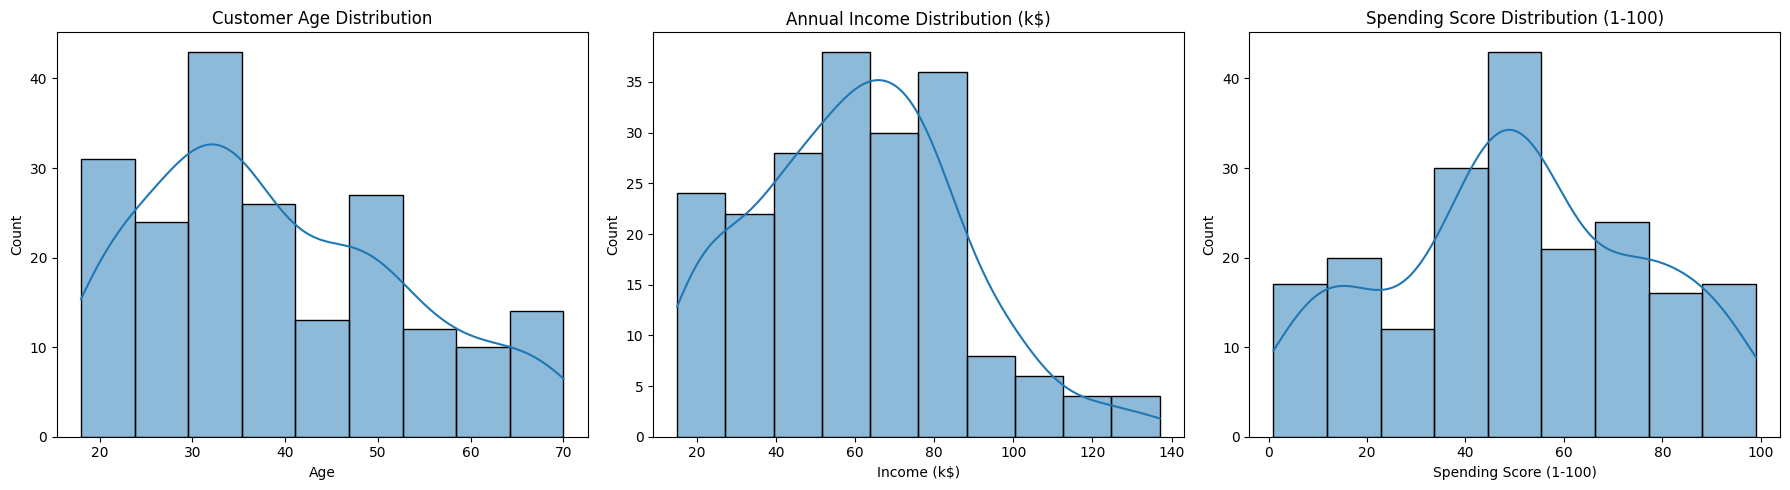

In [4]:
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
sns.histplot(df['Age'], kde=True)
plt.title("Customer Age Distribution")
plt.xlabel('Age')
plt.ylabel('Count')

plt.subplot(1, 3, 2)
sns.histplot(df['Annual Income (k$)'], kde=True)
plt.title("Annual Income Distribution (k$)")
plt.xlabel('Income (k$)')
plt.ylabel('Count')

plt.subplot(1, 3, 3)
sns.histplot(df['Spending Score (1-100)'], kde=True)
plt.title("Spending Score Distribution (1-100)")
plt.xlabel('Spending Score (1-100)')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

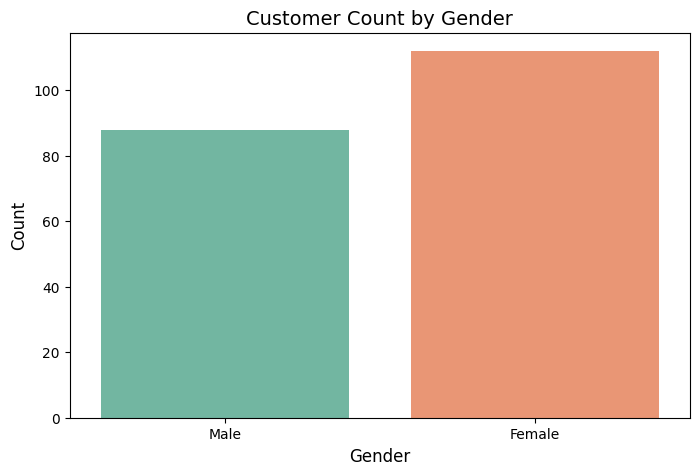

In [5]:
plt.figure(figsize=(8, 5))
sns.countplot(x='Gender', data=df, hue='Gender', palette='Set2', legend=False)
plt.title('Customer Count by Gender', fontsize=14)
plt.xlabel('Gender', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.show()

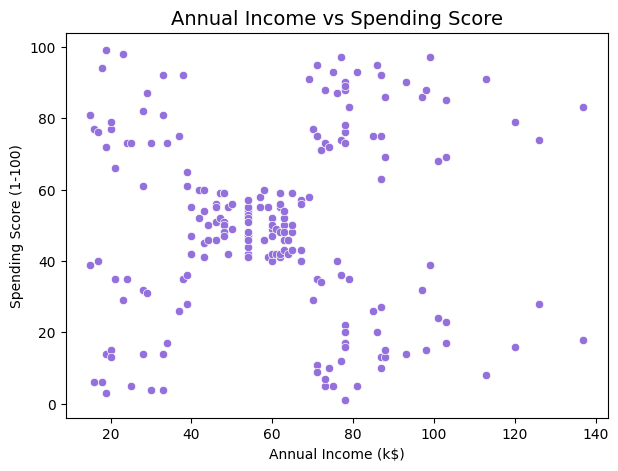

In [6]:
plt.figure(figsize=(7, 5))
sns.scatterplot(
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    data=df,
    color='mediumpurple'
)
plt.title("Annual Income vs Spending Score", fontsize=14)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()

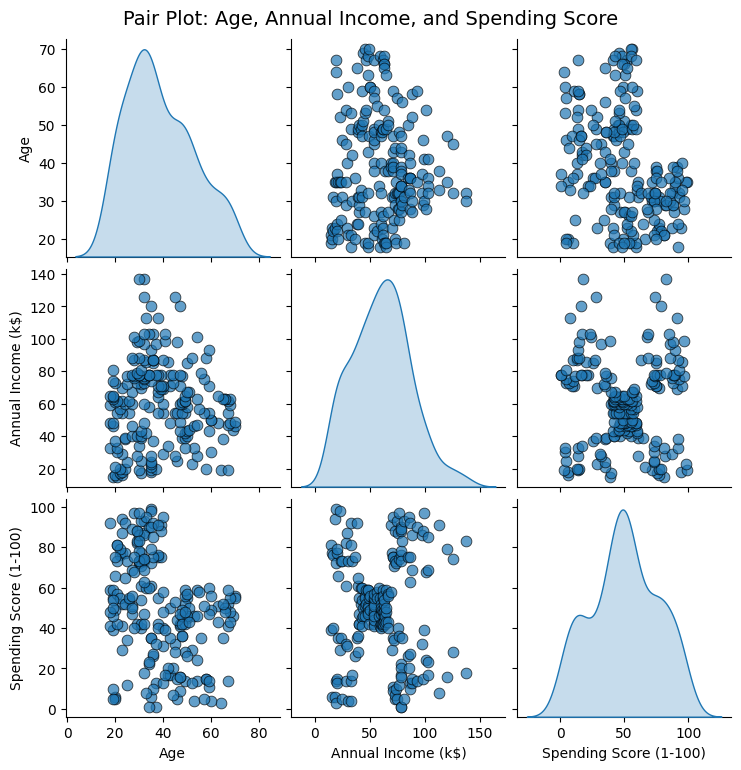

In [7]:
sns.pairplot(
    df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']],
    diag_kind='kde',
    plot_kws={'alpha': 0.7, 's': 60, 'edgecolor': 'k'}
)
plt.suptitle("Pair Plot: Age, Annual Income, and Spending Score", y=1.02, fontsize=14)
plt.show()

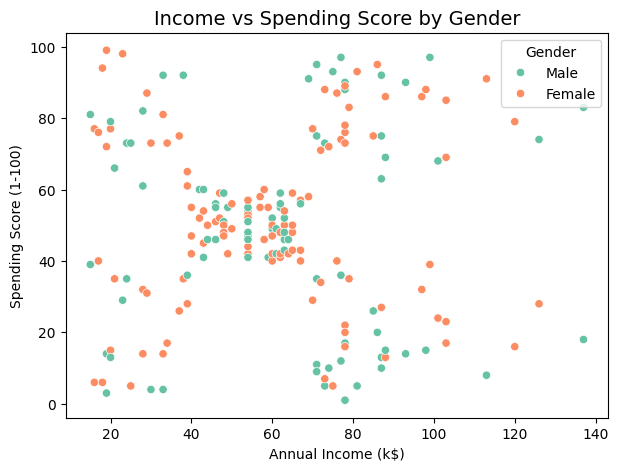

In [8]:
plt.figure(figsize=(7, 5))
sns.scatterplot(
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Gender',
    data=df,
    palette='Set2'
)
plt.title("Income vs Spending Score by Gender", fontsize=14)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title='Gender')
plt.show()

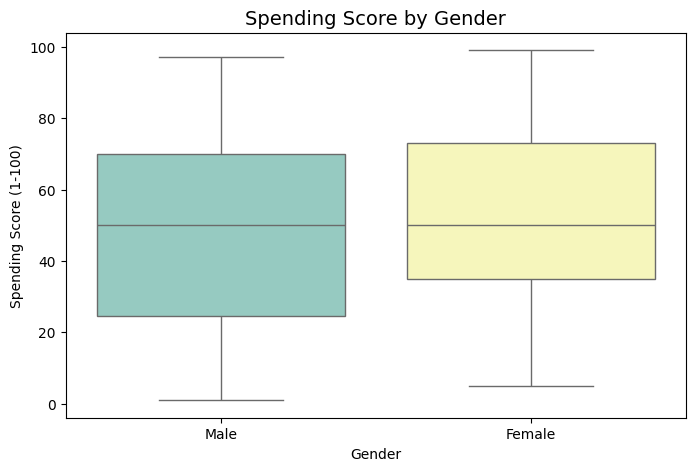

In [9]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Gender', y='Spending Score (1-100)', data=df, hue='Gender', palette='Set3', legend=False)
plt.title("Spending Score by Gender", fontsize=14)
plt.xlabel("Gender")
plt.ylabel("Spending Score (1-100)")
plt.show()

## C. Data checking and preparation

In [10]:
print("Duplicate rows:", df.duplicated().sum())
print(df.isnull().sum())

Duplicate rows: 0
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [11]:
df_prep = df.copy().drop_duplicates()
df_prep = df_prep.drop(columns=['CustomerID', 'Gender', 'Age'])
df_prep.isnull().sum()

Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [12]:
# Value ranges before scaling
features = ['Annual Income (k$)', 'Spending Score (1-100)']
df[features].describe()

,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000
mean,60.560000,50.200000
std,26.264721,25.823522
min,15.000000,1.000000
25%,41.500000,34.750000
50%,61.500000,50.000000
75%,78.000000,73.000000
max,137.000000,99.000000


In [13]:
# Value ranges before scaling
for col in features:
    print(f"{col}: {df[col].min():.2f} - {df[col].max():.2f}")

Annual Income (k$): 15.00 - 137.00
Spending Score (1-100): 1.00 - 99.00


In [14]:
# Standardization so that K-Means (distance-based) treats both features equally
scaler = StandardScaler()
df_scaled = df_prep.copy()
df_scaled[features] = scaler.fit_transform(df_prep[features])

df_scaled.head()

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


In [15]:
# Value ranges after scaling
for col in features:
    print(f"{col}: {df_scaled[col].min():.2f} - {df_scaled[col].max():.2f}")

Annual Income (k$): -1.74 - 2.92
Spending Score (1-100): -1.91 - 1.89


## D. Clustering - choosing k

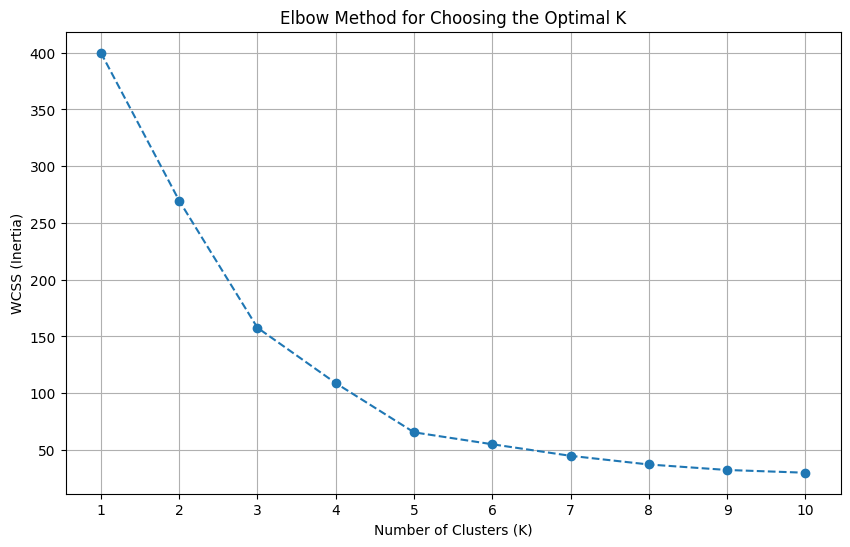

In [16]:
wcss = []
k_range = range(1, 11)
for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(df_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(k_range, wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Choosing the Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(k_range)
plt.grid(True)
plt.show()

## E. Evaluation - silhouette score

In [17]:
silhouette_scores = []
k_range_silhouette = range(2, 11)

for k in k_range_silhouette:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels = kmeans.fit_predict(df_scaled)
    score = silhouette_score(df_scaled, labels)
    silhouette_scores.append(score)
    print(f"K={k}, mean silhouette score: {score:.4f}")

optimal_k_silhouette = k_range_silhouette[np.argmax(silhouette_scores)]
print(f"Optimal K by silhouette score: {optimal_k_silhouette}")

K=2, mean silhouette score: 0.3213
K=3, mean silhouette score: 0.4666
K=4, mean silhouette score: 0.4939
K=5, mean silhouette score: 0.5547
K=6, mean silhouette score: 0.5399


K=7, mean silhouette score: 0.5281
K=8, mean silhouette score: 0.4552


K=9, mean silhouette score: 0.4571


K=10, mean silhouette score: 0.4432
Optimal K by silhouette score: 5


## F. Final model (K=5) and visualization

In [18]:
optimal_k = 5

kmeans_final = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
clusters = kmeans_final.fit_predict(df_scaled)

df_scaled['Cluster'] = clusters

print(df_scaled.head(10))

   Annual Income (k$)  Spending Score (1-100)  Cluster
0           -1.738999               -0.434801        4
1           -1.738999                1.195704        2
2           -1.700830               -1.715913        4
3           -1.700830                1.040418        2
4           -1.662660               -0.395980        4
5           -1.662660                1.001596        2
6           -1.624491               -1.715913        4
7           -1.624491                1.700384        2
8           -1.586321               -1.832378        4
9           -1.586321                0.846310        2


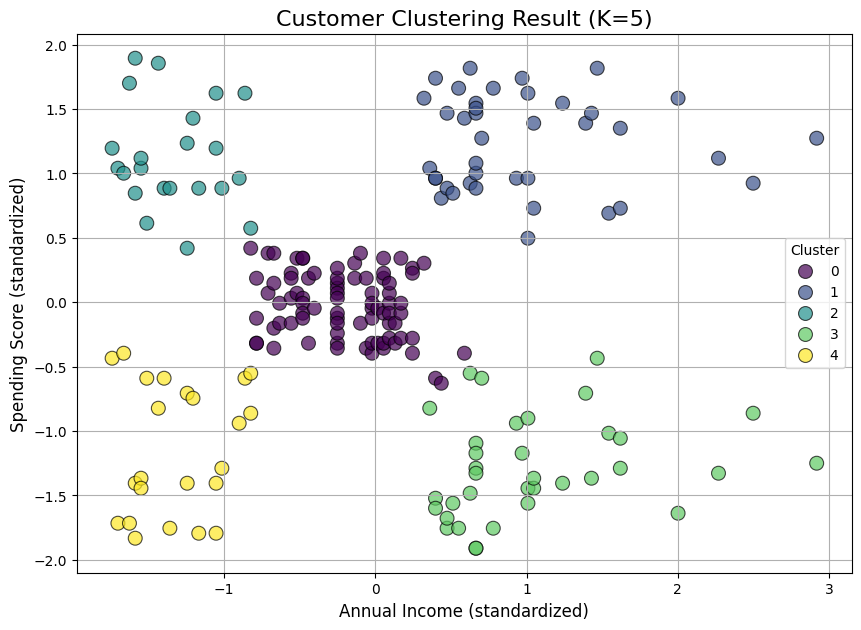

In [19]:
plt.figure(figsize=(10, 7))
sns.scatterplot(data=df_scaled,
                x='Annual Income (k$)',
                y='Spending Score (1-100)',
                hue='Cluster',
                palette='viridis',
                s=100,
                alpha=0.7,
                edgecolor='k')

plt.title(f'Customer Clustering Result (K={optimal_k})', fontsize=16)
plt.xlabel('Annual Income (standardized)', fontsize=12)
plt.ylabel('Spending Score (standardized)', fontsize=12)
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

## G. Cluster interpretation

Interpretation of the five clusters (based on the Module 9 report; cluster IDs can change between runs or library versions, so confirm against the scatter plot):

| Profile | Description | Suggested use |
|---|---|---|
| Low income, high spending score | Free spenders despite lower income | Promotions, loyalty programs |
| Mid income, mid spending score | Standard / average customers | Maintain |
| High income, low spending score | Wealthy but careful with spending | Quality, long-lasting products; financial products |
| High income, high spending score | Ideal customers (VIP) | Top priority |
| Low income, low spending score | Frugal with limited income | Lower priority |